# Color modelleri — Ortak değerlendirme

Bu notebook **model eğitimi yapmaz**. Random Forest, Logistic Regression, KNN ve Extra Trees notebook’larının kaydettiği sonuçları toplar; **Original ve Masked** sürümlerini karşılaştırır. Test seti kullanılmaz. Çıktı bulunmuyorsa ilgili model notebook’unu önce çalıştırın.

In [4]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
CURRENT_DIR=Path.cwd()
PROJECT_ROOT=CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
from src.config import BASE_DIR
RESULT_DIR=BASE_DIR/"outputs"/"models"/"color_optimized"
MODELS=["Random_Forest","Logistic_Regression","KNN","Extra_Trees"]

## 1 — Sonuçları birleştir

In [3]:
frames=[]
for name in MODELS:
    path=RESULT_DIR/f"{name}_summary.csv"
    if not path.exists():
        print(f"Eksik sonuç: {path.name}; önce model notebook'unu çalıştırın")
        continue
    frames.append(pd.read_csv(path))
if not frames:raise FileNotFoundError('Hiçbir model sonucu yok. Önce model notebooklarını çalıştırın.')
results=pd.concat(frames,ignore_index=True).sort_values('Val_Macro_F1',ascending=False)
cols=['Model','Variant','CV_Macro_F1','Train_Macro_F1','Val_Accuracy','Val_Macro_F1','Val_Macro_Precision','Val_Macro_Recall','MEL_Recall','MEL_Precision','Predicted_Classes','Best_Params']
display(results[cols].reset_index(drop=True))
results.to_csv(RESULT_DIR/'ALL_color_optimization_summary.csv',index=False)
print('Tamamlanan deney:',len(results),'/ 8')

,Model,Variant,CV_Macro_F1,Train_Macro_F1,Val_Accuracy,Val_Macro_F1,Val_Macro_Precision,Val_Macro_Recall,MEL_Recall,MEL_Precision,Predicted_Classes,Best_Params
0,Random_Forest,masked,0.495896,0.930806,0.739188,0.529634,0.542981,0.548506,0.520958,0.527273,7,"{""n_estimators"": 200, ""min_samples_split"": 10,..."
1,Extra_Trees,masked,0.487959,0.979544,0.752495,0.525452,0.555016,0.517912,0.419162,0.569106,7,"{""n_estimators"": 200, ""min_samples_split"": 2, ..."
2,Random_Forest,original,0.469018,0.961206,0.730539,0.460577,0.523743,0.451571,0.502994,0.444444,7,"{""n_estimators"": 200, ""min_samples_split"": 10,..."
3,Extra_Trees,original,0.457231,0.993772,0.744511,0.453607,0.569395,0.431068,0.437126,0.477124,7,"{""n_estimators"": 200, ""min_samples_split"": 2, ..."
4,Logistic_Regression,masked,0.404252,0.602134,0.705921,0.419884,0.462617,0.396574,0.227545,0.400000,7,"{""model__class_weight"": null, ""model__C"": 0.1}"
5,KNN,masked,0.379460,1.000000,0.730539,0.391581,0.479117,0.364201,0.221557,0.506849,7,"{""model__weights"": ""distance"", ""model__p"": 1, ..."
6,KNN,original,0.336888,1.000000,0.717898,0.373433,0.498716,0.330227,0.275449,0.494624,7,"{""model__weights"": ""distance"", ""model__p"": 1, ..."
7,Logistic_Regression,original,0.371655,0.639944,0.691284,0.369590,0.419491,0.345638,0.215569,0.367347,7,"{""model__class_weight"": null, ""model__C"": 1}"


Tamamlanan deney: 8 / 8


## 2 — Validation Macro F1 ve MEL Recall grafikleri

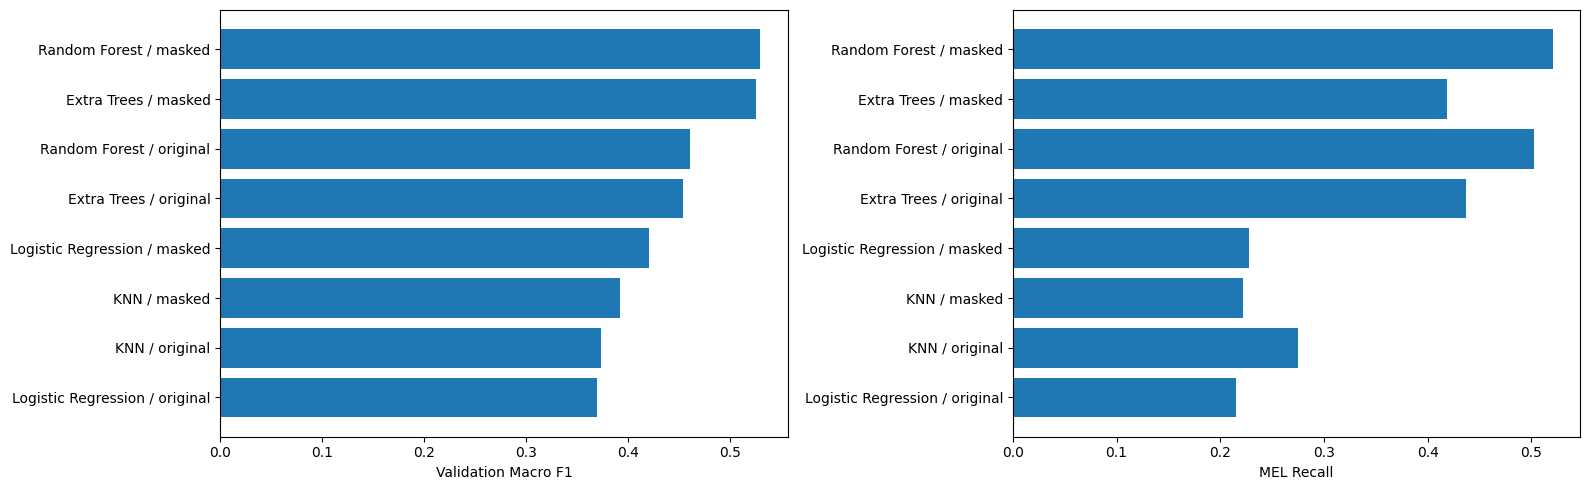

In [5]:
fig,axes=plt.subplots(1,2,figsize=(16,5))
labels=results['Model'].str.replace('_',' ')+' / '+results['Variant']
axes[0].barh(labels,results['Val_Macro_F1']);axes[0].invert_yaxis();axes[0].set_xlabel('Validation Macro F1')
axes[1].barh(labels,results['MEL_Recall']);axes[1].invert_yaxis();axes[1].set_xlabel('MEL Recall')
plt.tight_layout();plt.show()

## 3 — En yüksek Macro F1 sağlayan modeli ayrıntılı incele

En başarılı model: Random_Forest masked
Parametreler: {"n_estimators": 200, "min_samples_split": 10, "min_samples_leaf": 5, "max_features": 0.3, "max_depth": 25, "class_weight": "balanced"}
              precision    recall  f1-score   support

       AKIEC       0.38      0.49      0.43        49
         BCC       0.50      0.71      0.59        77
         BKL       0.44      0.48      0.46       165
          DF       0.50      0.17      0.25        18
         MEL       0.53      0.52      0.52       167
          NV       0.89      0.84      0.87      1006
        VASC       0.57      0.62      0.59        21

    accuracy                           0.74      1503
   macro avg       0.54      0.55      0.53      1503
weighted avg       0.75      0.74      0.74      1503



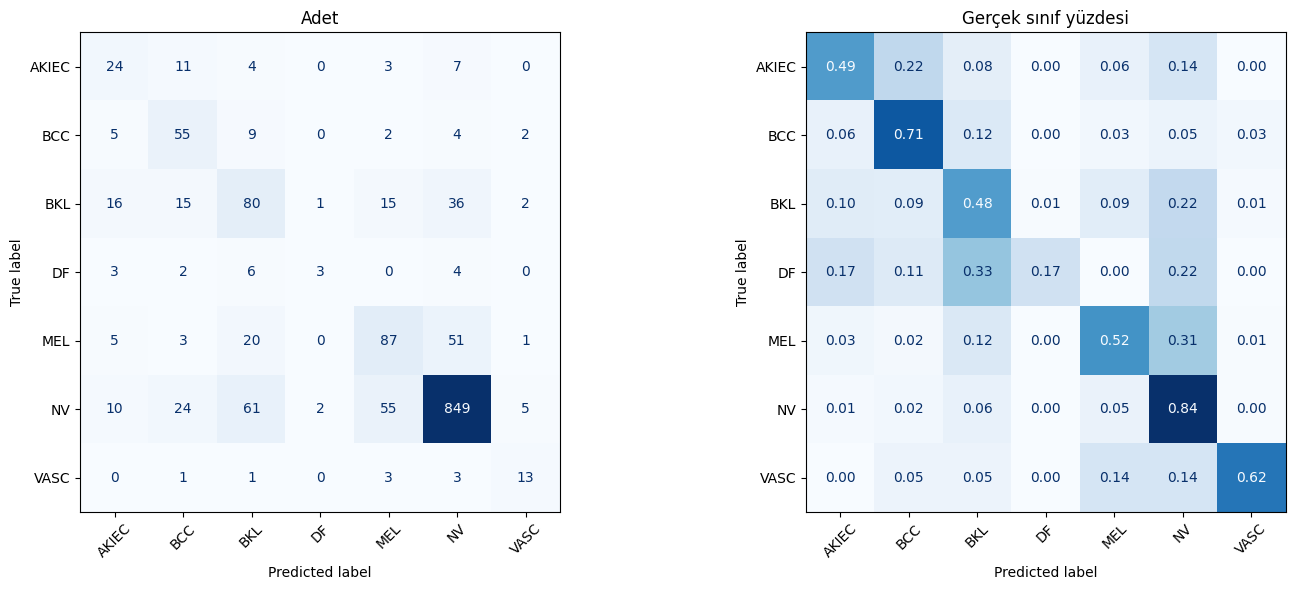

In [6]:
best=results.iloc[0]
name,variant=best['Model'],best['Variant']
path=RESULT_DIR/f'{name}_{variant}_val_predictions.csv'
preds=pd.read_csv(path,dtype={'image_id':str,'actual':str,'predicted':str})
classes=sorted(set(preds['actual'])|set(preds['predicted']))
print('En başarılı model:',name,variant)
print('Parametreler:',best['Best_Params'])
print(classification_report(preds['actual'],preds['predicted'],labels=classes,zero_division=0))
fig,axes=plt.subplots(1,2,figsize=(15,6))
for ax,norm,title,fmt in zip(axes,[None,'true'],['Adet','Gerçek sınıf yüzdesi'],['d','.2f']):
    cm=confusion_matrix(preds['actual'],preds['predicted'],labels=classes,normalize=norm)
    ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,cmap='Blues',values_format=fmt,colorbar=False)
    ax.set_title(title);ax.tick_params(axis='x',rotation=45)
plt.tight_layout();plt.show()

## 4 — Değerlendirme notları
- **CV Macro F1**, hiperparametre aramasının eğitim verisindeki ortalamasıdır. **Validation Macro F1** ayrı tutulan validation setindedir.
- **Test seti**, tüm seçimler tamamlanıncaya kadar saklanır. Tek seferlik final raporda kullanılır.
- Aynı lezyonun birden çok görüntüsü olma ihtimali nedeniyle split’in metadata bazlı kontrolü gerekir.
- **Masked** deneyleri gerçek maskeye bağımlıdır; otomatik segmentasyon olmadan klinik kullanım sonucu gibi yorumlanmamalıdır.
- Karşılaştırmanın geçerliliği için feature notebook’larının aynı görüntü ID sırasını ve aynı 439 özellik tanımını kullanması gerekir.

In [ ]:
import sys
if sys.platform == "win32":
    import winsound
    winsound.MessageBeep()
else:
    print("Ses bildirimi Windows için tanımlı; bu sistemde atlandı.")